- Source = https://www.quantifiedstrategies.com/pairs-trading-strategy-python/
- This is buy and hold strategy

### Import Libraries : Exhaustive list, not all being used

In [1]:
from PIL import Image

import os
dir_path = r"C:\Admin\C Drive\Desktop\CQF Course\Python Labs"

In [1]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# to reload another python script 
from importlib import reload

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use ='seaborn'
plt.rcParams['font.size'] = 8

# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

# Self organizing maps(SOM)
from minisom import MiniSom

# K-means clustering(KMC)
from sklearn.cluster import KMeans

# scikit learn(sklearn) package is used primarily for machine learning
# always remember to perform pre-processing and model selcetion before using model implementation
import sklearn
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split,TimeSeriesSplit,cross_val_score,GridSearchCV,RandomizedSearchCV

from sklearn.pipeline import Pipeline

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# Regression
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# Support Vector Machine(SVM)
from sklearn.svm import SVC

# DTEM(Decision Trees and Ensemble Models) - Bagging - Random Forest
from sklearn.ensemble import RandomForestClassifier

# DTEM(Decision Trees and Ensemble Models) - Boosting - Gradient Boosting(Extreme Gradient Boosting)
from xgboost import XGBClassifier,plot_importance,to_graphviz

# K nearest neighbours(KNN)
from sklearn.neighbors import KNeighborsClassifier

# Principal Component Analysis(PCA)
from sklearn.decomposition import PCA

# statistical analysis & optimization
import scipy.stats as scs
import scipy.optimize as sco

# statsmodels is a Python package that provides a complement to scipy for statistical computations
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Shapley values, used in DTEM
import shap

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf
 
# float display
pd.options.display.float_format = '{:0.4f}'.format

# Trading Strategy backtesting
import ffn

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

# Example 1 - Pair Trading based on Cointegration

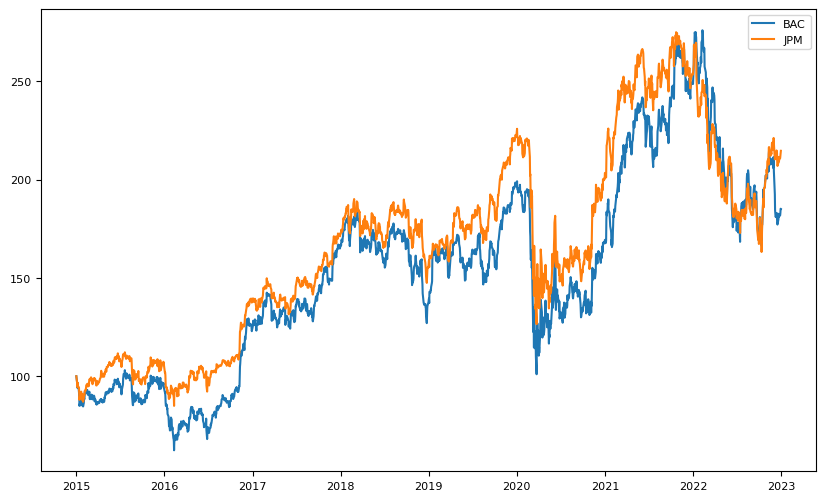

In [3]:
# download data
stock_1 = yf.download(tickers = 'BAC', start='2015-01-01', end='2023-01-01',progress =False)
stock_2 = yf.download(tickers = 'JPM', start='2015-01-01', end='2023-01-01',progress =False)

#checking relative prices
stock_1_norm = stock_1['Close']/stock_1['Close'].iloc[0]*100
stock_2_norm = stock_2['Close']/stock_2['Close'].iloc[0]*100

plt.plot(stock_1_norm, label = 'BAC')
plt.plot(stock_2_norm, label = 'JPM')
plt.legend()
plt.show()

## Pairs trading cointegration definition

If two time series are cointegrated, it means there exists a linear combination of these series of order I(1) that makes the residuals stationary of order I(0).

The following image has two time series: an integrated order 1 I(1) and an integrated order 0 I(0). The main difference is that the I(0) fluctuates horizontally, and the I(1) can have an upward or downward trend.

Two variables could move in the same direction, but it does not mean a long-run relationship between them. This phenomenon is called a spurious relationship. The cointegration test tries to find variables with long-run relationships.

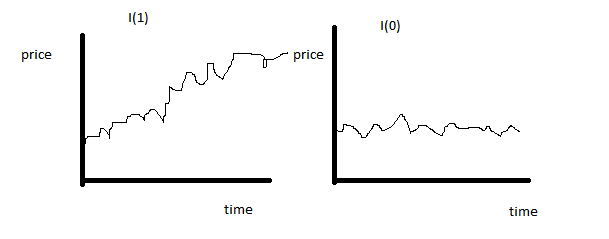

In [4]:
Image.open(os.path.join(dir_path, 'Cointegration_1.png'))

### Step 1 -The first step to test cointegration is to estimate a linear regression and get the spread:

In [5]:
# ordinary linear regression
Y= np.log(stock_2['Close'])
X = np.log(stock_1['Close'])

X = sm.add_constant(X)                      # sm.add_constant() - adds a column to dataframe (Y = aX +b)
model = sm.OLS(endog= Y,exog = X)           # sm.OLS() - initialize the model,exogenous variable - Y, endogenious variable - X
results = model.fit()                       # model.fit()

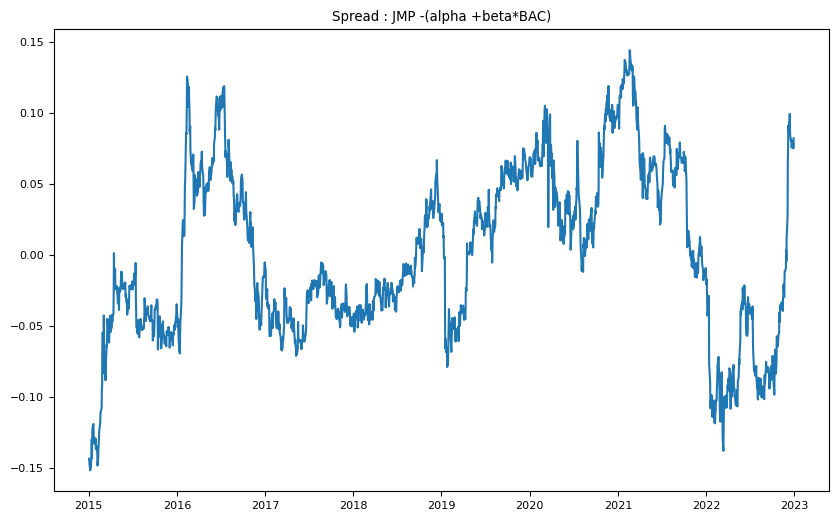

In [6]:
# get parameters
results.params                              # results.params
alpha = results.params[0]
beta = results.params[1]

# spread 
spread = Y - (alpha + beta* X['Close'])
plt.plot(spread)
plt.title('Spread : JMP -(alpha +beta*BAC)')
plt.show()

### Step 2 -The second part to test cointegration is to implement the Dickey-Fuller test:

In [7]:
adf_test = adfuller(x = spread, maxlag =1)                                          # adfuller() with maxlag
index = ['test statistics','p-value','# of lagged values','# of observations']
adf_output = pd.Series(adf_test[0:4],index = index)

critical_values = pd.Series(adf_test[4],index = adf_test[4].keys())
print(adf_output)
print(critical_values)

test statistics        -3.1110
p-value                 0.0258
# of lagged values      0.0000
# of observations    2013.0000
dtype: float64
1%    -3.4336
5%    -2.8630
10%   -2.5675
dtype: float64


### Step 3 -The Z-score and Signal for pairs trading

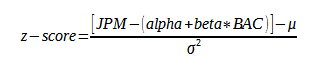

In [8]:
Image.open(os.path.join(dir_path, 'Cointegration_2.png'))

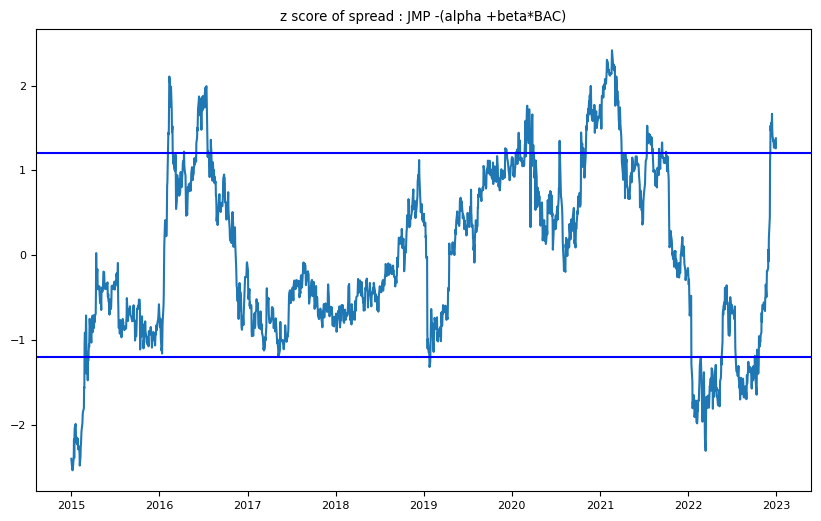

In [9]:
z_score = (spread -np.mean(spread))/np.std(spread)
plt.plot(z_score)
plt.title('z score of spread : JMP -(alpha +beta*BAC)')
plt.axhline(y = 1.2, color = 'blue')
plt.axhline(y = -1.2, color = 'blue')
plt.show()

The previous chart shows the normalized residuals; they fluctuate around zero, where the minimum and maximum values go from -2.3 to 2.3. Setting thresholds to the z-score in pairs trading is necessary to identify the moment to place operations. Values that are outside those levels indicate that there is a divergence in price between the two financial instruments. The previous chart had ass thresholds 1.2 and -1.2.

Pairs trading trading rules (entry and exit points)
Consider the spread equation , where and . A positive spread is when . It means JPM > BAC; therefore, each time the spread or the z-score is positive, JPM > BAC. Remember, JPM is the winner stock, and BAC is the loser stock.

The entry and exit rules in the strategy are:

**Long the spread**: place a short position in JPM (winner stock) and a long position in BAC (loser stock) when the z-score crosses 1.2 from below, and there is no position.

**Short the spread**: place a long position in JPM (loser stock) and a short position in BAC (winner stock) when the z-score crosses 1.2 from above and there is no position.

**Exit position**: Exit the spread every time the z-score crosses 0, and there is no position.

In [10]:
bt_test = pd.DataFrame()
signal_entry = 1.2
signal_exit = 0

bt_test['stock_2'] = stock_2['Close']
bt_test['stock_1'] = stock_1['Close']
bt_test['short_signal'] = (z_score > signal_entry) & (z_score.shift(1) < signal_entry) 
bt_test['short_exit'] = (z_score < signal_exit) & (z_score.shift(1) > signal_exit) 
bt_test['long_signal'] = (z_score < -signal_entry) & (z_score.shift(1) > -signal_entry) 
bt_test['long_exit'] = (z_score > -signal_exit) & (z_score.shift(1) < -signal_exit) 

### Step 4 - Trading Strategy

In [11]:
spread_side = None
counter = -1
backtest_result = []
indicator = 0

for time, signal_stock in  bt_test.iterrows():
    counter += 1
    stock_1, stock_2, short_signal,short_exit,long_signal,long_exit = signal_stock
    
    if spread_side == None:
        return_stock_2 = 0
        return_stock_1 = 0
        backtest_result.append([time,return_stock_2,return_stock_1,spread_side])
        
        if short_signal == True:
            spread_side = 'short'
        elif long_signal == True:
            spread_side = 'long'
    
    elif spread_side == 'long':
        return_stock_2 = (bt_test['stock_2'][counter] / bt_test['stock_2'][counter-1]) - 1
        return_stock_1 = (bt_test['stock_1'][counter] / bt_test['stock_1'][counter-1]) - 1
        backtest_result.append([time,return_stock_2,-return_stock_1,spread_side])
        
        if long_exit == True:
            spread_side = None
                          
    elif spread_side == 'short':
        return_stock_2 = (bt_test['stock_2'][counter] / bt_test['stock_2'][counter-1]) - 1
        return_stock_1 = (bt_test['stock_1'][counter] / bt_test['stock_1'][counter-1]) - 1
        backtest_result.append([time,-return_stock_2,return_stock_1,spread_side])
        
        if short_exit == True:
            spread_side = None

### Summary

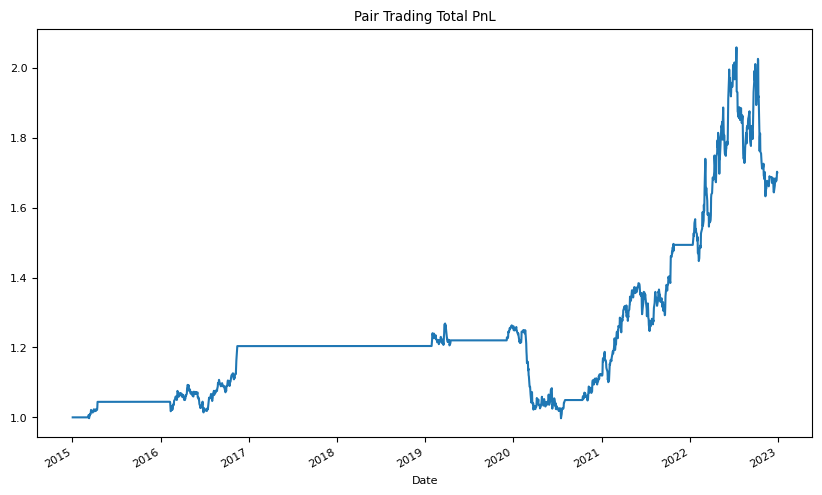

In [12]:
df_backtest_result = pd.DataFrame(backtest_result)
df_backtest_result.columns = ['Date','Stock_2_Return', 'Stock_1_Return', 'Side']

df_backtest_result['Stock_2_PL'] = np.cumprod(df_backtest_result['Stock_2_Return'] + 1)
df_backtest_result['Stock_1_PL'] = np.cumprod(df_backtest_result['Stock_1_Return'] + 1)
df_backtest_result['Total_PL'] = (df_backtest_result['Stock_2_PL']  + df_backtest_result['Stock_1_PL'])/2
df_backtest_result.set_index('Date',drop = True, inplace=True)      

df_backtest_result['Total_PL'].plot()
plt.title('Pair Trading Total PnL')
plt.show()